# Introduction to the USPTO Patent File Wrapper API

The USPTO Open Data Portal provides programmatic access to patent application information through APIs.

In this workbook, we will use the USPTO Patent File Wrapper API to:

- retrieve information about a single patent application
- inspect the JSON returned by the API
- search patent application data using a technology term
- select useful information from the search results
- create a pandas DataFrame
- examine Cooperative Patent Classification (CPC) codes
- make a simple visualization

This workbook follows the same basic workflow as the introductory OpenAlex API workbook:

**known record → API → JSON → search → JSON → pandas → visualization**

The goal is to become comfortable accessing and exploring USPTO data programmatically. More complicated patent landscape analysis can come later.


## 1. Setup

We will use:

- `requests` to communicate with the USPTO API
- `yaml` to read an API key from a configuration file
- `pandas` to work with tabular data
- `matplotlib` through pandas for a simple visualization

The USPTO Open Data Portal API requires an API key.

For this workshop, store the key in a file named `config.yml` in the same directory as this notebook:

```yaml
api_key: YOUR_USPTO_API_KEY
```

Keeping the key outside the notebook makes it easier to avoid accidentally publishing it with teaching materials.


In [2]:
import requests
import yaml
import pandas as pd

with open("config.yml", "r") as f:
    config = yaml.safe_load(f)

API_KEY = config["uspto_api_key"]

BASE_URL = "https://api.uspto.gov/api/v1/patent/applications"

headers = {
    "X-API-KEY": API_KEY,
    "Accept": "application/json"
}


## 2. Retrieve a Single Patent Application

We will begin with one known patent application.

The example uses application number **15/694,515**, written without punctuation as `15694515` for the API.

This application is associated with a patent involving large-scale supply-chain planning and mathematical optimization.


In [3]:
APPLICATION_NUMBER = "15694515"

url = f"{BASE_URL}/{APPLICATION_NUMBER}"

response = requests.get(url, headers=headers)
response.raise_for_status()

application = response.json()


### Look at the JSON

Before extracting anything, look at the complete response.

JSON returned by the API becomes Python data structures that we can inspect and manipulate.


In [4]:
application


{'count': 1,
 'patentFileWrapperDataBag': [{'grantDocumentMetaData': {'productIdentifier': 'PTGRXML',
    'zipFileName': 'ipg190618.zip',
    'fileCreateDateTime': '2024-09-30T14:24:37',
    'xmlFileName': '15694515_10325237.xml',
    'fileLocationURI': 'https://api.uspto.gov/api/v1/datasets/products/files/PTGRXML-SPLT/2019/ipg190618/15694515_10325237.xml'},
   'eventDataBag': [{'eventCode': 'N423',
     'eventDescriptionText': 'Post Issue Communication - Certificate of Correction',
     'eventDate': '2023-06-06'},
    {'eventCode': 'M1554',
     'eventDescriptionText': 'Surcharge for Late Payment, Large Entity',
     'eventDate': '2023-06-05'},
    {'eventCode': 'M1551',
     'eventDescriptionText': 'Payment of Maintenance Fee, 4th Year, Large Entity',
     'eventDate': '2023-06-05'},
    {'eventCode': 'REM.',
     'eventDescriptionText': 'Maintenance Fee Reminder Mailed',
     'eventDate': '2023-02-06'},
    {'eventCode': 'PGM/',
     'eventDescriptionText': 'Recordation of Patent Gr

In [5]:
type(application)


dict

In [6]:
application.keys()


dict_keys(['count', 'patentFileWrapperDataBag', 'requestIdentifier'])

The application records returned by this API are stored in `patentFileWrapperDataBag`.

For this request, we expect one matching application.


In [7]:
application["patentFileWrapperDataBag"]


[{'grantDocumentMetaData': {'productIdentifier': 'PTGRXML',
   'zipFileName': 'ipg190618.zip',
   'fileCreateDateTime': '2024-09-30T14:24:37',
   'xmlFileName': '15694515_10325237.xml',
   'fileLocationURI': 'https://api.uspto.gov/api/v1/datasets/products/files/PTGRXML-SPLT/2019/ipg190618/15694515_10325237.xml'},
  'eventDataBag': [{'eventCode': 'N423',
    'eventDescriptionText': 'Post Issue Communication - Certificate of Correction',
    'eventDate': '2023-06-06'},
   {'eventCode': 'M1554',
    'eventDescriptionText': 'Surcharge for Late Payment, Large Entity',
    'eventDate': '2023-06-05'},
   {'eventCode': 'M1551',
    'eventDescriptionText': 'Payment of Maintenance Fee, 4th Year, Large Entity',
    'eventDate': '2023-06-05'},
   {'eventCode': 'REM.',
    'eventDescriptionText': 'Maintenance Fee Reminder Mailed',
    'eventDate': '2023-02-06'},
   {'eventCode': 'PGM/',
    'eventDescriptionText': 'Recordation of Patent Grant Mailed',
    'eventDate': '2019-06-18'},
   {'eventCode'

In [8]:
record = application["patentFileWrapperDataBag"][0]
record.keys()


dict_keys(['grantDocumentMetaData', 'eventDataBag', 'applicationMetaData', 'parentContinuityBag', 'patentTermAdjustmentData', 'assignmentBag', 'pgpubDocumentMetaData', 'lastIngestionDateTime', 'childContinuityBag', 'recordAttorney', 'applicationNumberText', 'correspondenceAddressBag'])

Much of the information we will use is stored inside `applicationMetaData`.


In [9]:
metadata = record["applicationMetaData"]
metadata


{'firstInventorToFileIndicator': 'N',
 'applicationStatusCode': 150,
 'applicationTypeCode': 'UTL',
 'entityStatusData': {'smallEntityStatusIndicator': False,
  'businessEntityStatusCategory': 'Regular Undiscounted'},
 'filingDate': '2017-09-01',
 'uspcSymbolText': '705/28',
 'nationalStageIndicator': False,
 'firstInventorName': 'Narasimha B. Kamath',
 'cpcClassificationBag': ['G06Q  10/06', 'G06Q  10/0633'],
 'effectiveFilingDate': '2017-09-01',
 'publicationDateBag': ['2017-12-21'],
 'publicationSequenceNumberBag': ['0364847'],
 'earliestPublicationDate': '2017-12-21',
 'applicationTypeLabelName': 'Utility',
 'applicationStatusDate': '2019-05-29',
 'class': '705',
 'applicationTypeCategory': 'REGULAR',
 'inventorBag': [{'firstName': 'Narasimha',
   'lastName': 'Kamath',
   'inventorNameText': 'Narasimha B. Kamath',
   'middleName': 'B.',
   'correspondenceAddressBag': [{'cityName': 'Bangalore',
     'countryCode': 'IN',
     'nameLineOneText': 'Kamath, Narasimha B.',
     'countryNa

In [10]:
metadata.keys()


dict_keys(['firstInventorToFileIndicator', 'applicationStatusCode', 'applicationTypeCode', 'entityStatusData', 'filingDate', 'uspcSymbolText', 'nationalStageIndicator', 'firstInventorName', 'cpcClassificationBag', 'effectiveFilingDate', 'publicationDateBag', 'publicationSequenceNumberBag', 'earliestPublicationDate', 'applicationTypeLabelName', 'applicationStatusDate', 'class', 'applicationTypeCategory', 'inventorBag', 'applicationStatusDescriptionText', 'patentNumber', 'grantDate', 'applicantBag', 'firstApplicantName', 'customerNumber', 'groupArtUnitNumber', 'earliestPublicationNumber', 'inventionTitle', 'applicationConfirmationNumber', 'examinerNameText', 'subclass', 'publicationCategoryBag', 'docketNumber'])

Now retrieve a few recognizable fields.


In [11]:
print("Title:", metadata.get("inventionTitle"))
print("Filing date:", metadata.get("filingDate"))
print("Application type:", metadata.get("applicationTypeLabelName"))
print("Status:", metadata.get("applicationStatusDescriptionText"))
print("First inventor:", metadata.get("firstInventorName"))
print("First applicant:", metadata.get("firstApplicantName"))
print("Publication number:", metadata.get("earliestPublicationNumber"))


Title: System and Method for Solving Large Scale Supply Chain Planning Problems with Integer Constraints
Filing date: 2017-09-01
Application type: Utility
Status: Patented Case
First inventor: Narasimha B. Kamath
First applicant: JDA Software Group, Inc.
Publication number: US20170364847A1


### Inventors

Some USPTO fields contain nested information. For example, `inventorBag` contains information about the inventors associated with the application.


In [12]:
metadata.get("inventorBag", [])


[{'firstName': 'Narasimha',
  'lastName': 'Kamath',
  'inventorNameText': 'Narasimha B. Kamath',
  'middleName': 'B.',
  'correspondenceAddressBag': [{'cityName': 'Bangalore',
    'countryCode': 'IN',
    'nameLineOneText': 'Kamath, Narasimha B.',
    'countryName': 'INDIA',
    'postalAddressCategory': 'residence'},
   {'cityName': 'Bangalore',
    'countryCode': 'IN',
    'nameLineOneText': 'Narasimha B. Kamath',
    'countryName': 'INDIA',
    'postalAddressCategory': 'postal'}]},
 {'firstName': 'Tushar',
  'lastName': 'Shekhar',
  'inventorNameText': 'Tushar Shekhar',
  'correspondenceAddressBag': [{'cityName': 'Bangalore',
    'countryCode': 'IN',
    'nameLineOneText': 'Shekhar, Tushar',
    'countryName': 'INDIA',
    'postalAddressCategory': 'residence'},
   {'cityName': 'Bangalore',
    'countryCode': 'IN',
    'nameLineOneText': 'Tushar  Shekhar',
    'countryName': 'INDIA',
    'postalAddressCategory': 'postal'}]}]

In [13]:
for inventor in metadata.get("inventorBag", []):
    print(inventor.get("inventorNameText"))


Narasimha B. Kamath
Tushar Shekhar


### Cooperative Patent Classification (CPC)

Patent applications can have one or more **Cooperative Patent Classification (CPC)** codes.

CPC is a hierarchical classification system used to organize inventions according to technological subject matter. For now, we will simply inspect the codes returned by the API. Understanding and interpreting the classification system in greater detail can come later.


In [14]:
metadata.get("cpcClassificationBag", [])


['G06Q  10/06', 'G06Q  10/0633']

At this point, we have not performed a patent landscape analysis. We have simply learned how to retrieve a USPTO application record and investigate some of the information available in it.


## 3. Search USPTO Patent Application Data

Often we do not begin with a known application number. Instead, we want to find patent applications related to a technology or research area.

For this example, we will search for:

**Supply Chain Nonlinear Optimization**

The variable below is deliberately easy to change. After completing the example, replace it with a technology or research area that interests you.


In [15]:
SEARCH_TERM = "Supply Chain Nonlinear Optimization"


In [16]:
search_url = f"{BASE_URL}/search"

search_headers = {
    "X-API-KEY": API_KEY,
    "Content-Type": "application/json",
    "Accept": "application/json"
}

payload = {
    "q": SEARCH_TERM
}

response = requests.post(
    search_url,
    headers=search_headers,
    json=payload
)

response.raise_for_status()

results = response.json()


## 4. Inspect the Search Results

As before, start by looking at the JSON rather than immediately converting it into a table.


In [17]:
results


{'count': 109405,
 'patentFileWrapperDataBag': [{'eventDataBag': [{'eventCode': 'NWREIBHA',
     'eventDescriptionText': 'Receipt of New Application from I.B. (Hague)',
     'eventDate': '2026-10-23'},
    {'eventCode': 'BIG.',
     'eventDescriptionText': 'Entity Status Set To Undiscounted (Initial Default Setting or Status Change)',
     'eventDate': '2026-10-23'},
    {'eventCode': 'IEXX',
     'eventDescriptionText': 'Initial Exam Team nn',
     'eventDate': '2026-10-23'}],
   'applicationMetaData': {'applicationStatusCode': 19,
    'applicationTypeCode': 'DES',
    'entityStatusData': {'smallEntityStatusIndicator': False,
     'businessEntityStatusCategory': 'Regular Undiscounted'},
    'filingDate': '2026-09-29',
    'applicationStatusDescriptionText': 'Application Undergoing Preexam Processing',
    'internationalRegistrationPublicationDate': '2026-10-23',
    'groupArtUnitNumber': '2913',
    'inventionTitle': 'Energy storage power supply',
    'nationalStageIndicator': False,


In [18]:
results.keys()


dict_keys(['count', 'patentFileWrapperDataBag', 'requestIdentifier'])

The matching patent application records are stored in `patentFileWrapperDataBag`.


In [19]:
applications = results["patentFileWrapperDataBag"]

type(applications)


list

In [20]:
len(applications)


25

Look at the first returned record.


In [21]:
applications[0]


{'eventDataBag': [{'eventCode': 'NWREIBHA',
   'eventDescriptionText': 'Receipt of New Application from I.B. (Hague)',
   'eventDate': '2026-10-23'},
  {'eventCode': 'BIG.',
   'eventDescriptionText': 'Entity Status Set To Undiscounted (Initial Default Setting or Status Change)',
   'eventDate': '2026-10-23'},
  {'eventCode': 'IEXX',
   'eventDescriptionText': 'Initial Exam Team nn',
   'eventDate': '2026-10-23'}],
 'applicationMetaData': {'applicationStatusCode': 19,
  'applicationTypeCode': 'DES',
  'entityStatusData': {'smallEntityStatusIndicator': False,
   'businessEntityStatusCategory': 'Regular Undiscounted'},
  'filingDate': '2026-09-29',
  'applicationStatusDescriptionText': 'Application Undergoing Preexam Processing',
  'internationalRegistrationPublicationDate': '2026-10-23',
  'groupArtUnitNumber': '2913',
  'inventionTitle': 'Energy storage power supply',
  'nationalStageIndicator': False,
  'applicationConfirmationNumber': 2158,
  'effectiveFilingDate': '2026-09-29',
  'a

Now print the invention titles from the first ten results.


In [22]:
for item in applications[:10]:
    meta = item.get("applicationMetaData", {})
    print(meta.get("inventionTitle"))


Energy storage power supply
Modular Power Supply
LIQUID EJECTING APPARATUS WITH A LIQUID STORAGE TANK, A VALVE TO OPEN AND TO CLOSE A SUPPLY PATH, AND A VALVE LEVER HANDLE OPERABLE BY A USER
SECONDARY BATTERY ELECTRODE FILM AND SEPARATOR SUPPLY DEVICE
SECONDARY BATTERY ELECTRODE FILM AND SEPARATOR SUPPLY DEVICE
POWER SUPPLY DEVICE
LIGHT TUBE WITH ANTI-ELECTRIC SHOCK PROTECTION FUNCTION AND CAPABLE OF BEING SUPPLIED WITH ELECTRICITY BY ELECTRICAL BALLAST AND ALTERNATE-CURRENT POWER SUPPLY IN WORKING FREQUENCY
Decentralized Swarm-Learning Prevention of Software Application Defects Using Particle Swarm Optimization and Blockchain Smart Contracts
Design Optimization For A Medical Device
ARCHIVING PLUG-IN OPTIMIZATION


### Single record versus search results

The pattern should look familiar from OpenAlex:

- requesting a known application returned a specific Patent File Wrapper record
- searching returned a collection of matching application records

The field names and structure differ between information systems, but the general API workflow is similar.


## 5. Build a pandas DataFrame

USPTO application records contain much more information than we need for every analysis.

For this example, we will select:

- invention title
- filing date
- first inventor
- first applicant
- application type
- application status
- earliest publication number

This lets us move from nested JSON into a simple tabular dataset.


In [23]:
records = []

for item in applications:
    meta = item.get("applicationMetaData", {})

    records.append({
        "title": meta.get("inventionTitle"),
        "filing_date": meta.get("filingDate"),
        "first_inventor": meta.get("firstInventorName"),
        "first_applicant": meta.get("firstApplicantName"),
        "application_type": meta.get("applicationTypeLabelName"),
        "status": meta.get("applicationStatusDescriptionText"),
        "publication_number": meta.get("earliestPublicationNumber")
    })

df = pd.DataFrame(records)

df.head()


,title,filing_date,first_inventor,first_applicant,application_type,status,publication_number
0,Energy storage power supply,2026-09-29,None,None,Design,Application Undergoing Preexam Processing,None
1,Modular Power Supply,2026-08-20,Thomas J Cummings,BAE Systems Controls Inc,Re-Issue,Docketed New Case - Ready for Examination,None
2,LIQUID EJECTING APPARATUS WITH A LIQUID STORAG...,2026-08-03,Nobuhiro Toki,CANON KABUSHIKI KAISHA,Re-Issue,Docketed New Case - Ready for Examination,None
3,SECONDARY BATTERY ELECTRODE FILM AND SEPARATOR...,2026-07-17,Kye-Seol LEE,None,Utility,Docketed New Case - Ready for Examination,US20260351656A1
4,SECONDARY BATTERY ELECTRODE FILM AND SEPARATOR...,2026-07-17,Kye-Seol LEE,None,Utility,Docketed New Case - Ready for Examination,US20260351655A1


In [24]:
df.shape


(25, 7)

In [25]:
df.columns


Index(['title', 'filing_date', 'first_inventor', 'first_applicant',
       'application_type', 'status', 'publication_number'],
      dtype='object')

## 6. Examine CPC Codes in the Search Results

The CPC information is nested inside each patent application record, so we will collect the classification codes separately.

A single patent application can have multiple CPC codes. As a result, the number of classification records may be larger than the number of patent applications returned by the search.


In [27]:
cpc_codes = []

for item in applications:
    meta = item.get("applicationMetaData", {})

    for cpc in meta.get("cpcClassificationBag", []):
        if cpc:
            cpc_codes.append(cpc)

cpc_codes[:20]

['B65H  19/102',
 'H01M  10/0409',
 'Y02P  70/50',
 'H01M  50/461',
 'B65H  19/1852',
 'B65H2301/413226',
 'B65H2301/4173',
 'B65H2301/41734',
 'B65H2301/41856',
 'B65H2301/44352',
 'B65H2301/46042',
 'B65H2301/46075',
 'B65H2301/4631',
 'B65H2406/343',
 'B65H2701/132',
 'B65H2801/72',
 'H01M  10/0587',
 'H01M2220/20',
 'Y02E  60/10',
 'B65H  19/102']

Create a small DataFrame containing the CPC codes.


In [28]:
cpc_df = pd.DataFrame(cpc_codes, columns=["cpc"])

cpc_df.head()


,cpc
0,B65H 19/102
1,H01M 10/0409
2,Y02P 70/50
3,H01M 50/461
4,B65H 19/1852


Count the most frequently occurring CPC codes in the returned records.


In [29]:
cpc_counts = cpc_df["cpc"].value_counts().head(15)

cpc_counts


G06N  20/00       3
B65H  19/102      2
B65H2301/4631     2
G06Q  30/0283     2
H01M  10/0409     2
G06N   7/01       2
Y02E  60/10       2
H01M2220/20       2
H01M  10/0587     2
B65H2801/72       2
B65H2701/132      2
B65H2406/343      2
G06Q  20/4016     2
B65H2301/46075    2
B65H2301/44352    2
Name: cpc, dtype: int64

## 7. Visualize the Most Common CPC Codes

A horizontal bar chart works well here because CPC codes are categorical values.

This visualization describes the classifications found among the patent application records returned by our search.


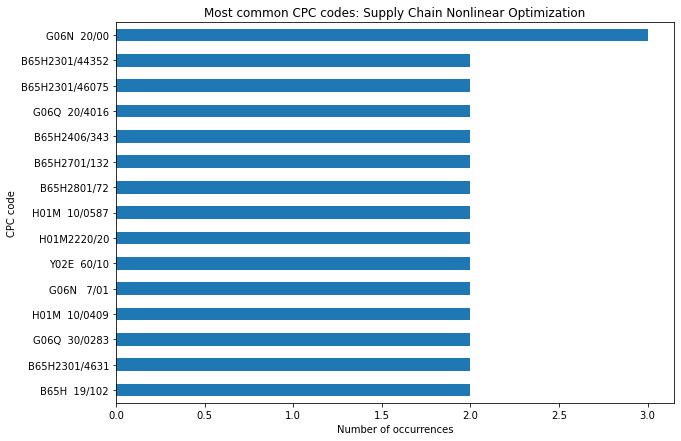

In [30]:
cpc_counts.sort_values().plot(
    kind="barh",
    xlabel="Number of occurrences",
    ylabel="CPC code",
    title=f"Most common CPC codes: {SEARCH_TERM}",
    figsize=(10, 7)
);


### A note about interpretation

This chart describes only the CPC codes found in the patent application records returned by **this API request**.

It should not yet be interpreted as a complete patent landscape.

However, the classifications give us another way to think about the search results. A keyword search finds records based on text, while CPC codes organize inventions according to technological subject matter.

Questions we might investigate later include:

- What do these CPC codes mean?
- Are the classifications consistent with what we expected from our keyword search?
- Would classification-based searching identify additional relevant patents?
- At what level of the CPC hierarchy should classifications be compared?
- How could CPC classifications help define a patent landscape?


## 8. Try Your Own Search

Now change the value of `SEARCH_TERM` and rerun the search sections of the workbook.

For example:

```python
SEARCH_TERM = "drug delivery nanoparticle"
```

or:

```python
SEARCH_TERM = "medical image segmentation"
```

Better yet, choose a technology or research area from your own work or interests.

After rerunning the search, consider:

1. Do the returned invention titles appear relevant to your topic?
2. Who appears as an inventor or applicant?
3. What CPC codes appear most frequently?
4. Are some patents associated with several CPC classifications?
5. What other information in the JSON might be useful?
6. What would you want to change or add before treating these results as a patent landscape?

As the mathematics textbooks say, interpreting the CPC codes in greater detail is left as an exercise for the reader.


## 9. What We Did

In this workbook, we followed a simple computational patent-information workflow:

**Patent application → API request → JSON**

and then:

**Technology term → API search → JSON → selected fields → pandas DataFrame → CPC classifications → visualization**

The important goal is not the particular application or search term. Once you understand the pattern, you can change the query and begin exploring USPTO patent information related to your own interests.

Later work can build on this foundation with more precise search syntax, classifications, inventors, applicants and assignees, larger result sets, patent documents, and relationships among patent and research information.
